# Praktikum Minggu 9 — Clustering

## Nomor 1 — Membaca dan Menampilkan Dataset

In [12]:
import pandas as pd

dataset = pd.read_csv('transaction.csv')

print (dataset)

       InvoiceNo  StockCode  Qty      InvoiceDate  CustomerID  \
0         537626      22725  830  12/7/2010 14:57       12347   
1         537626      22729  948  12/7/2010 14:57       12347   
2         537626      22195  695  12/7/2010 14:57       12347   
3         542237      22725  636  1/26/2011 14:30       12347   
4         542237      22729  536  1/26/2011 14:30       12347   
...          ...        ...  ...              ...         ...   
10541     543911      21700  455  2/14/2011 12:46       17829   
10542     543911      22111  578  2/14/2011 12:46       17829   
10543     543911      22112  163  2/14/2011 12:46       17829   
10544     564428      23296  545  8/25/2011 11:27       17844   
10545     564428      23294  643  8/25/2011 11:27       17844   

                    Country  
0                   Iceland  
1                   Iceland  
2                   Iceland  
3                   Iceland  
4                   Iceland  
...                     ...  
10541  Un

## Nomor 2 — Menghitung kemunculan setiap negara pada dataset

In [13]:
country = dataset['Country'].value_counts()

print(country)

Country
Germany                 2269
France                  2109
EIRE                    1620
Netherlands              634
Spain                    539
Belgium                  486
Switzerland              434
Portugal                 367
Australia                356
Norway                   239
Italy                    190
Channel Islands          184
Finland                  152
Cyprus                   113
Sweden                   109
Denmark                   98
Japan                     92
Austria                   88
Poland                    80
Israel                    61
USA                       47
Singapore                 45
Unspecified               44
Canada                    36
Iceland                   35
Greece                    33
United Arab Emirates      23
Malta                     15
RSA                       14
Brazil                     8
Lithuania                  8
Lebanon                    5
European Community         5
Czech Republic             4
Bahrai

## Nomor 3 — Menghitung jumlah transaksi tiap negara

In [14]:
transaksi = pd.DataFrame(
    dataset.groupby("Country")["InvoiceNo"].nunique()
).rename(columns={"InvoiceNo": "Jumlah Transaksi"})

print(transaksi)


                      Jumlah Transaksi
Country                               
Australia                           44
Austria                             12
Bahrain                              1
Belgium                             84
Brazil                               1
Canada                               3
Channel Islands                     21
Cyprus                              16
Czech Republic                       2
Denmark                             18
EIRE                               224
European Community                   3
Finland                             26
France                             344
Germany                            377
Greece                               5
Iceland                              6
Israel                               4
Italy                               31
Japan                               14
Lebanon                              1
Lithuania                            2
Malta                                2
Netherlands              

## Nomor 4 — Clustering transaksi dengan Average Linkage, k = 3

In [15]:
from sklearn.cluster import AgglomerativeClustering

model = AgglomerativeClustering(
    n_clusters=3,
    linkage="average"
)

cluster = model.fit_predict(transaksi[["Jumlah Transaksi"]].to_numpy())

transaksi["Cluster"] = cluster

print(transaksi)

                      Jumlah Transaksi  Cluster
Country                                        
Australia                           44        0
Austria                             12        0
Bahrain                              1        0
Belgium                             84        0
Brazil                               1        0
Canada                               3        0
Channel Islands                     21        0
Cyprus                              16        0
Czech Republic                       2        0
Denmark                             18        0
EIRE                               224        2
European Community                   3        0
Finland                             26        0
France                             344        1
Germany                            377        1
Greece                               5        0
Iceland                              6        0
Israel                               4        0
Italy                               31  

## Nomor 5 — Menentukan centroid setiap cluster

In [16]:
centroid = transaksi.groupby("Cluster")["Jumlah Transaksi"].mean()

print(centroid)

Cluster
0     18.787879
1    360.500000
2    224.000000
Name: Jumlah Transaksi, dtype: float64


## Nomor 6 — Mengurutkan centroid secara ascending

In [17]:
centroid_sorted = centroid.sort_values()

print(centroid_sorted)

Cluster
0     18.787879
2    224.000000
1    360.500000
Name: Jumlah Transaksi, dtype: float64


## Nomor 7 — Menampilkan negara dengan transaksi rendah, sedang, dan tinggi

In [18]:
kategori = dict(zip(
    centroid_sorted.index,
    ["Rendah", "Sedang", "Tinggi"]
))

transaksi["Kategori"] = transaksi["Cluster"].map(kategori)

for tingkat in ["Rendah", "Sedang", "Tinggi"]:
    print(f"\nTransaksi {tingkat}:")
    print(transaksi.loc[
        transaksi["Kategori"] == tingkat,
        ["Jumlah Transaksi", "Kategori"]
    ])


Transaksi Rendah:
                      Jumlah Transaksi Kategori
Country                                        
Australia                           44   Rendah
Austria                             12   Rendah
Bahrain                              1   Rendah
Belgium                             84   Rendah
Brazil                               1   Rendah
Canada                               3   Rendah
Channel Islands                     21   Rendah
Cyprus                              16   Rendah
Czech Republic                       2   Rendah
Denmark                             18   Rendah
European Community                   3   Rendah
Finland                             26   Rendah
Greece                               5   Rendah
Iceland                              6   Rendah
Israel                               4   Rendah
Italy                               31   Rendah
Japan                               14   Rendah
Lebanon                              1   Rendah
Lithuania            

In [19]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## Nomor 8 — Visualisasi hasil clustering

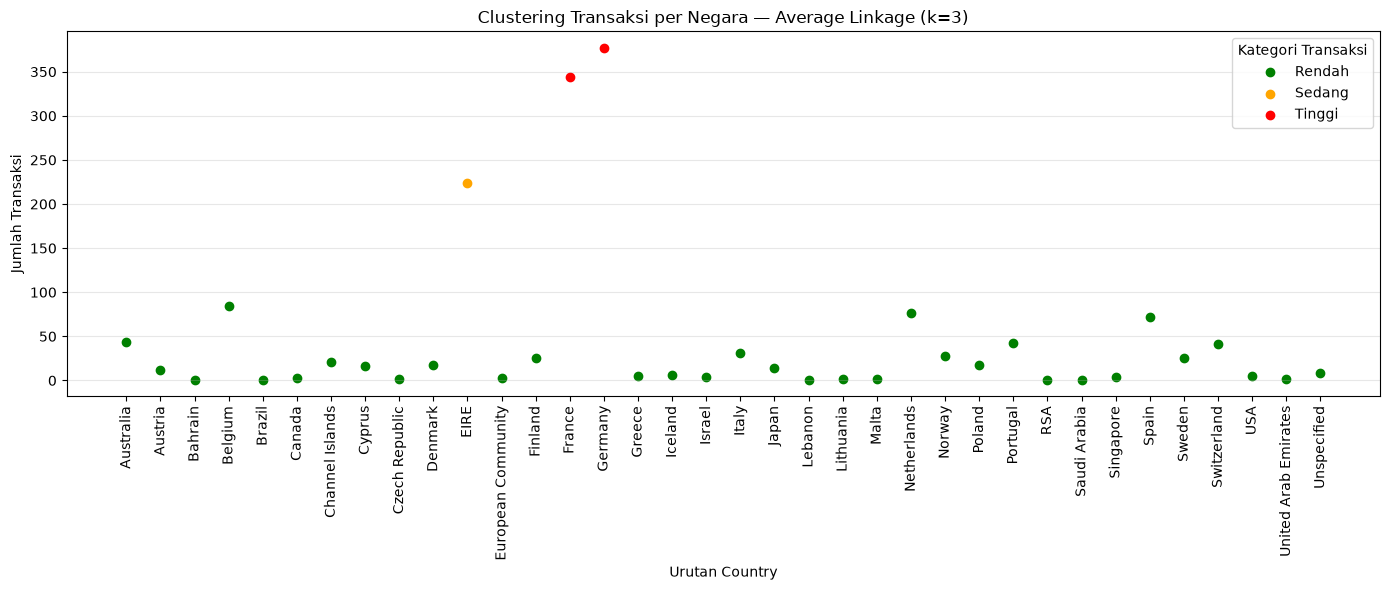

In [20]:
import matplotlib.pyplot as plt
import numpy as np

urutan_country = np.arange(len(transaksi))

warna = {
    "Rendah": "green",
    "Sedang": "orange",
    "Tinggi": "red"
}

plt.figure(figsize=(14, 6))

for kategori, warna_cluster in warna.items():
    anggota = transaksi["Kategori"] == kategori

    plt.scatter(
        urutan_country[anggota],
        transaksi.loc[anggota, "Jumlah Transaksi"],
        color=warna_cluster,
        label=kategori
    )

plt.xticks(
    urutan_country,
    [str(negara) for negara in transaksi.index],
    rotation=90
)

plt.xlabel("Urutan Country")
plt.ylabel("Jumlah Transaksi")
plt.title("Clustering Transaksi per Negara — Average Linkage (k=3)")
plt.legend(title="Kategori Transaksi")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()